<a href="https://colab.research.google.com/github/mademoisellecastellanos/Proyecto-RappiPlus-de-datos-a-decisiones-de-negocio/blob/main/S12_Estudiante_Proyecto_Final_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import numpy as np


In [ ]:
# cargar archivos
orders = pd.read_csv('/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('/datasets/rappiplus_marketing_spend.csv')

In [ ]:
# explorar datasets
print("Dimensiones iniciales:")
print(f"Orders: {orders.shape}")
print(f"Catalog: {catalog.shape}")
print(f"Marketing: {marketing.shape}")

Dimensiones iniciales:
Orders: (25100, 12)
Catalog: (7, 4)
Marketing: (1620, 5)


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas

---

In [ ]:
# tu código aquí
# 1. Asegurar que las columnas numéricas sean tratadas como números (convirtiendo textos raros a NaN)
orders['cantidad'] = pd.to_numeric(orders['cantidad'], errors='coerce')
orders['precio_unitario'] = pd.to_numeric(orders['precio_unitario'], errors='coerce')
orders['monto_descuento'] = pd.to_numeric(orders['monto_descuento'], errors='coerce')
orders['monto_total'] = pd.to_numeric(orders['monto_total'], errors='coerce')

# 2. Eliminar registros nulos en campos clave del negocio
orders.dropna(subset=['id_pedido', 'id_usuario', 'nombre_producto'], inplace=True)

# 3. Rellenar nulos categóricos y numéricos básicos
orders['pais'] = orders['pais'].fillna('Desconocido')
orders['dispositivo'] = orders['dispositivo'].fillna('Desconocido')
orders['fuente_referencia'] = orders['fuente_referencia'].fillna('Desconocido')
orders['categoria_producto'] = orders['categoria_producto'].fillna('Desconocido')
orders['cantidad'] = orders['cantidad'].fillna(1.0)
orders['monto_descuento'] = orders['monto_descuento'].fillna(0.0)

# 4. RECALCULAR EL MONTO TOTAL DE FORMA CORRECTA
# Evita los números masivos o corruptos calculándolo matemáticamente: (cantidad * precio) - descuento
orders['precio_unitario'] = orders['precio_unitario'].fillna(orders['monto_total'] / orders['cantidad'])
orders['monto_total'] = (orders['cantidad'] * orders['precio_unitario']) - orders['monto_descuento']

# 5. FILTRAR ANOMALÍAS (Eliminar cantidades negativas y montos absurdos o negativos)
# Esto limpia las devoluciones erróneas y los picos de errores de sistema
orders = orders[(orders['cantidad'] > 0) & (orders['monto_total'] > 0) & (orders['monto_total'] < 50000)]

# 6. Eliminar duplicados exactos
orders.drop_duplicates(inplace=True)

# 7. Exportar los datasets limpios definitivos
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

print("¡Limpieza y validación completada con éxito sin datos corruptos!")


¡Limpieza y validación completada con éxito sin datos corruptos!


In [ ]:
marketing['gasto'] = pd.to_numeric(marketing['gasto'], errors='coerce')
marketing['gasto'].fillna(marketing['gasto'].median(), inplace=True)
marketing['canal'].fillna('desconocido', inplace=True)
marketing.drop_duplicates(inplace=True)

In [ ]:
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)
print("¡Datasets limpios y exportados con éxito!")

¡Datasets limpios y exportados con éxito!


---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [ ]:
# tu código aquí
orders_merged = orders.merge(catalog[['nombre_producto', 'costo_unitario']], on='nombre_producto', how='left')
orders_merged['costo_total_orden'] = orders_merged['cantidad'] * orders_merged['costo_unitario']

In [ ]:
total_revenue = orders_merged['monto_total'].sum()
total_cost = orders_merged['costo_total_orden'].sum()
total_marketing = marketing['gasto'].sum()
ganancia_bruta = total_revenue - total_cost
ganancia_neta = ganancia_bruta - total_marketing


print(f"💰 Ingreso Total (Revenue): ${total_revenue:,.2f}")
print(f"📦 Costo Total de Productos: ${total_cost:,.2f}")
print(f"📢 Inversión Total en Marketing: ${total_marketing:,.2f}")
print(f"📈 Ganancia Bruta: ${ganancia_bruta:,.2f}")
print(f"🚀 Ganancia Neta (considerando marketing): ${ganancia_neta:,.2f}")

💰 Ingreso Total (Revenue): $9,631,647.78
📦 Costo Total de Productos: $3,832,997.75
📢 Inversión Total en Marketing: $2,871,843.53
📈 Ganancia Bruta: $5,798,650.03
🚀 Ganancia Neta (considerando marketing): $2,926,806.50


In [ ]:
avg_ticket = orders_merged['monto_total'].mean()
avg_quantity = orders_merged['cantidad'].mean()
top_product = orders_merged['nombre_producto'].value_counts().idxmax()
marketing_by_channel = marketing.groupby('canal')['gasto'].sum()

print(f"\nTicket promedio por orden: ${avg_ticket:,.2f}")
print(f"Cantidad promedio de productos por orden: {avg_quantity:.2f}")
print(f"Producto más vendido: {top_product}")
print("\nGasto en marketing por canal:\n", marketing_by_channel)


Ticket promedio por orden: $385.95
Cantidad promedio de productos por orden: 1.50
Producto más vendido: Blender-XL-Red

Gasto en marketing por canal:
 canal
desconocido    177179.10
organic        913533.01
paid_search    863088.21
social         918043.21
Name: gasto, dtype: float64


In [ ]:
avg_ticket = orders_merged['monto_total'].mean()
avg_quantity = orders_merged['cantidad'].mean()
top_product = orders_merged['nombre_producto'].value_counts().idxmax()
marketing_by_channel = marketing.groupby('canal')['gasto'].sum()

print(f"\nTicket promedio por orden: ${avg_ticket:,.2f}")
print(f"Cantidad promedio de productos por orden: {avg_quantity:.2f}")
print(f"Producto más vendido: {top_product}")
print("\nGasto en marketing por canal:\n", marketing_by_channel)


Ticket promedio por orden: $385.95
Cantidad promedio de productos por orden: 1.50
Producto más vendido: Blender-XL-Red

Gasto en marketing por canal:
 canal
desconocido    177179.10
organic        913533.01
paid_search    863088.21
social         918043.21
Name: gasto, dtype: float64


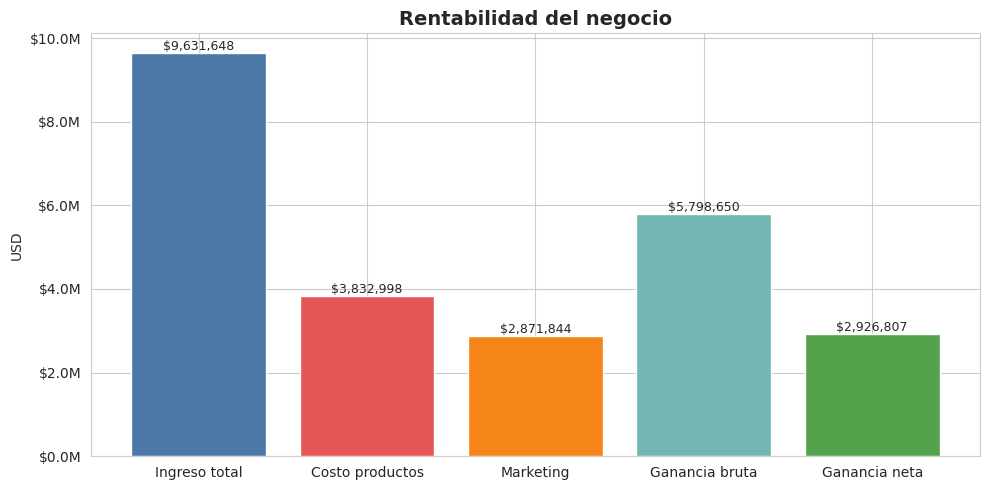

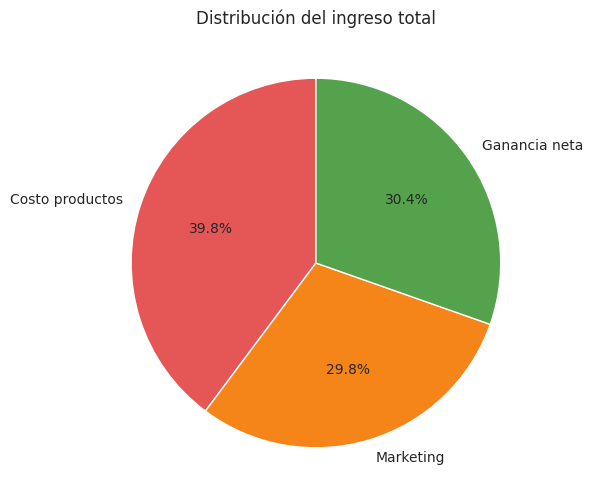

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

sns.set_style("whitegrid")

# --- Gráfica 1: Ingresos, costos, marketing y ganancia ---
labels = ['Ingreso total', 'Costo productos', 'Marketing', 'Ganancia bruta', 'Ganancia neta']
values = [total_revenue, total_cost, total_marketing, ganancia_bruta, ganancia_neta]
colors = ['#4C78A8', '#E45756', '#F58518', '#72B7B2', '#54A24B']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, values, color=colors)
ax.set_title('Rentabilidad del negocio', fontsize=14, fontweight='bold')
ax.set_ylabel('USD')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v, f'${v:,.0f}',
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

# --- Gráfica 2: ¿A dónde se va cada dólar de ingreso? ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie([total_cost, total_marketing, ganancia_neta],
       labels=['Costo productos', 'Marketing', 'Ganancia neta'],
       autopct='%1.1f%%', startangle=90,
       colors=['#E45756', '#F58518', '#54A24B'])
ax.set_title('Distribución del ingreso total')
plt.show()

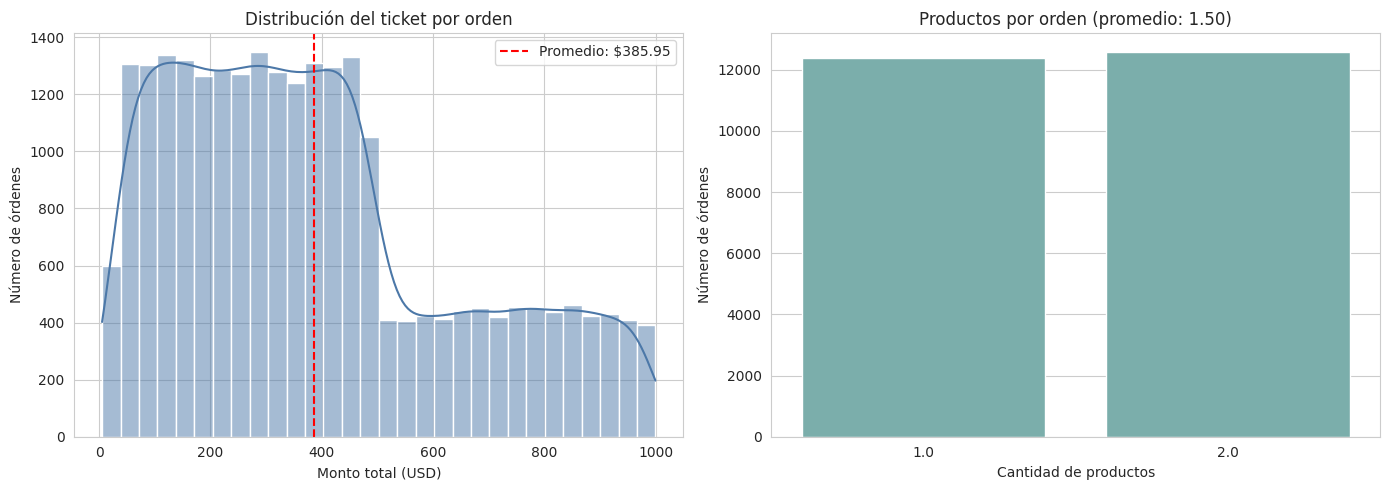

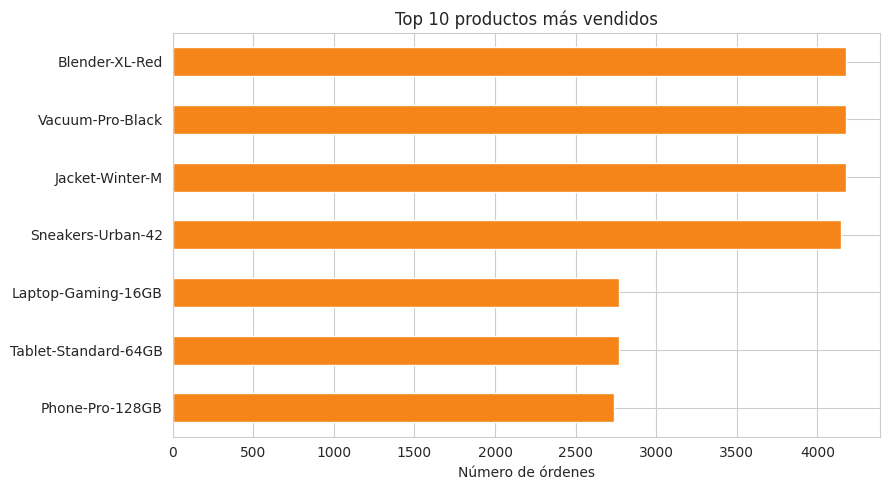

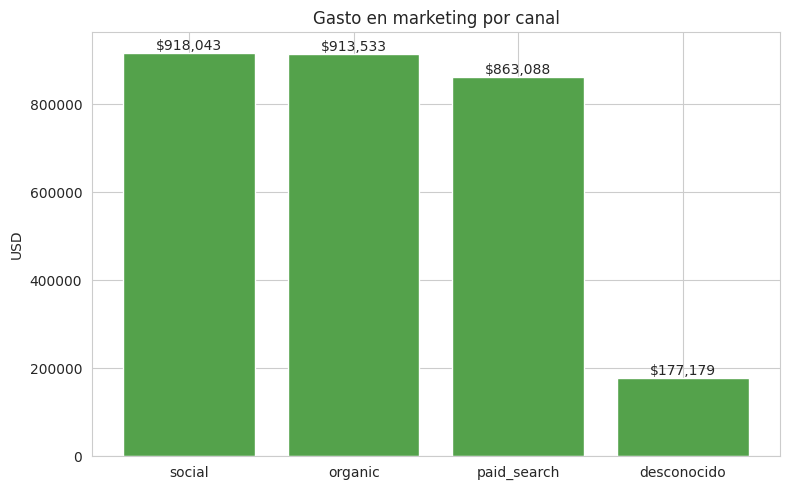

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(orders_merged['monto_total'], bins=30, kde=True, ax=axes[0], color='#4C78A8')
axes[0].axvline(avg_ticket, color='red', linestyle='--', label=f'Promedio: ${avg_ticket:,.2f}')
axes[0].set_title('Distribución del ticket por orden')
axes[0].set_xlabel('Monto total (USD)')
axes[0].set_ylabel('Número de órdenes')
axes[0].legend()

sns.countplot(x='cantidad', data=orders_merged, ax=axes[1], color='#72B7B2')
axes[1].set_title(f'Productos por orden (promedio: {avg_quantity:.2f})')
axes[1].set_xlabel('Cantidad de productos')
axes[1].set_ylabel('Número de órdenes')

plt.tight_layout()
plt.show()

# --- Top 10 productos más vendidos ---
top10 = orders_merged['nombre_producto'].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
top10.plot(kind='barh', ax=ax, color='#F58518')
ax.set_title('Top 10 productos más vendidos')
ax.set_xlabel('Número de órdenes')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

# --- Gasto en marketing por canal ---
mkt = marketing_by_channel.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(mkt.index, mkt.values, color='#54A24B')
ax.set_title('Gasto en marketing por canal')
ax.set_ylabel('USD')
for bar, v in zip(bars, mkt.values):
    ax.text(bar.get_x() + bar.get_width()/2, v, f'${v:,.0f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Interpretación de resultados:
**Rentabilidad del negocio**
Se tiene un ingreso de 9,631,648.00 de los cuales el
39.8% se va en costo del producto y el otro 29.8% se va en marketing, que vienen siendo laos gastos mas altos,
a pesar de ello, el negocio si es rentable con una ganancia neta de $2,926,807.00.

**Comportamiento de ventas**
El ticket promedio es de $385.95 y se compran 1.5 productos por orden: son compras de pocas unidades pero de valor relativamente alto.

**Conclusión**
El negocio genera ganancias (≈ 30 % de margen neto), pero el costo de marketing es alto,
como consiguiente paso conviene medir el retorno por canal (ingreso generado vs. gasto)
para reasignar presupuesto hacia los canales más eficientes y depurar el canal desconocido.

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [ ]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT
nombre_evento,
    COUNT(DISTINCT id_usuario) AS usuarios_unicos
FROM events
GROUP BY nombre_evento
ORDER BY CASE nombre_evento
    WHEN 'first_visit'      THEN 1
    WHEN 'select_item'      THEN 2
    WHEN 'add_to_cart'      THEN 3
    WHEN 'begin_checkout'   THEN 4
    WHEN 'add_payment_info' THEN 5
    WHEN 'purchase'         THEN 6
END;
'''
totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


In [ ]:
# PARTE 2: Conversiones
# ======================


query_conversion = '''
WITH usuario_pasos AS (
    -- Una fila por usuario: 1 si realizó el evento alguna vez, 0 si no
    SELECT
        id_usuario,
        MAX(CASE WHEN nombre_evento = 'first_visit'      THEN 1 ELSE 0 END) AS p1,
        MAX(CASE WHEN nombre_evento = 'select_item'      THEN 1 ELSE 0 END) AS p2,
        MAX(CASE WHEN nombre_evento = 'add_to_cart'      THEN 1 ELSE 0 END) AS p3,
        MAX(CASE WHEN nombre_evento = 'begin_checkout'   THEN 1 ELSE 0 END) AS p4,
        MAX(CASE WHEN nombre_evento = 'add_payment_info' THEN 1 ELSE 0 END) AS p5,
        MAX(CASE WHEN nombre_evento = 'purchase'         THEN 1 ELSE 0 END) AS p6
    FROM events
    GROUP BY id_usuario
),
funnel AS (
    -- Funnel acumulado: en cada paso solo cuentan los usuarios que pasaron por TODOS los pasos anteriores
    SELECT 1 AS orden, CAST('first_visit' AS TEXT)      AS nombre_evento, COUNT(*) AS usuarios FROM usuario_pasos WHERE p1 = 1
    UNION ALL
    SELECT 2, CAST('select_item' AS TEXT),      COUNT(*) FROM usuario_pasos WHERE p1 = 1 AND p2 = 1
    UNION ALL
    SELECT 3, CAST('add_to_cart' AS TEXT),      COUNT(*) FROM usuario_pasos WHERE p1 = 1 AND p2 = 1 AND p3 = 1
    UNION ALL
    SELECT 4, CAST('begin_checkout' AS TEXT),   COUNT(*) FROM usuario_pasos WHERE p1 = 1 AND p2 = 1 AND p3 = 1 AND p4 = 1
    UNION ALL
    SELECT 5, CAST('add_payment_info' AS TEXT), COUNT(*) FROM usuario_pasos WHERE p1 = 1 AND p2 = 1 AND p3 = 1 AND p4 = 1 AND p5 = 1
    UNION ALL
    SELECT 6, CAST('purchase' AS TEXT),         COUNT(*) FROM usuario_pasos WHERE p1 = 1 AND p2 = 1 AND p3 = 1 AND p4 = 1 AND p5 = 1 AND p6 = 1
)
SELECT
    orden,
    nombre_evento,
    usuarios,
    LAG(usuarios) OVER (ORDER BY orden) AS paso_anterior,
    ROUND(usuarios * 100.0 / LAG(usuarios) OVER (ORDER BY orden), 2) AS tasa_conversion_paso,
    ROUND(usuarios * 100.0 / FIRST_VALUE(usuarios) OVER (ORDER BY orden), 2) AS tasa_acumulada
FROM funnel
ORDER BY orden;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,orden,nombre_evento,usuarios,paso_anterior,tasa_conversion_paso,tasa_acumulada
0,1,first_visit,7796,NaN,NaN,100.00
1,2,select_item,7393,7796.0,94.83,94.83
2,3,add_to_cart,7052,7393.0,95.39,90.46
3,4,begin_checkout,6364,7052.0,90.24,81.63
4,5,add_payment_info,4967,6364.0,78.05,63.71
5,6,purchase,3857,4967.0,77.65,49.47


<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Aquí hay que revisar cómo se está calculando las conversiones ya que lo esperado es conforme avance en el embudo la conversión disminuya entonces se debe explciar por qué de una etapa a otra puede subir en lugar de bajar cómo pasa con `select_item`, también te recomendaría agregar visualizaciones para que exponer los resultados sea más sencillo que solo exponer un resultado numérico.

Para complementar también deberías dejar una celda markdown con tus interpretaciones.
</div>

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM user_activity
LIMIT 3;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity
LIMIT 3;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH user_cohorts AS (
    SELECT
        id_usuario,
        DATE_TRUNC('month', CAST(fecha_registro AS DATE)) AS mes_cohorte
    FROM users
),
activity_weeks AS (
    SELECT
        ua.id_usuario,
        uc.mes_cohorte,
        EXTRACT(WEEK FROM CAST(ua.fecha_actividad AS DATE)) - EXTRACT(WEEK FROM CAST(uc.mes_cohorte AS DATE)) AS numero_semana
    FROM user_activity ua
    JOIN user_cohorts uc ON ua.id_usuario = uc.id_usuario
)
SELECT
    mes_cohorte,
    COUNT(DISTINCT id_usuario) AS total_usuarios_cohorte,
    COUNT(DISTINCT CASE WHEN numero_semana = 1 THEN id_usuario END) AS retenido_w1,
    COUNT(DISTINCT CASE WHEN numero_semana = 2 THEN id_usuario END) AS retenido_w2,
    COUNT(DISTINCT CASE WHEN numero_semana = 3 THEN id_usuario END) AS retenido_w3
FROM activity_weeks
GROUP BY mes_cohorte
ORDER BY mes_cohorte;
'''


# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,mes_cohorte,total_usuarios_cohorte,retenido_w1,retenido_w2,retenido_w3
0,2025-01-01 00:00:00+00:00,1627,236,587,949
1,2025-02-01 00:00:00+00:00,1444,89,494,858
2,2025-03-01 00:00:00+00:00,1636,105,468,834
3,2025-04-01 00:00:00+00:00,1606,313,692,1060
4,2025-05-01 00:00:00+00:00,1687,222,601,965


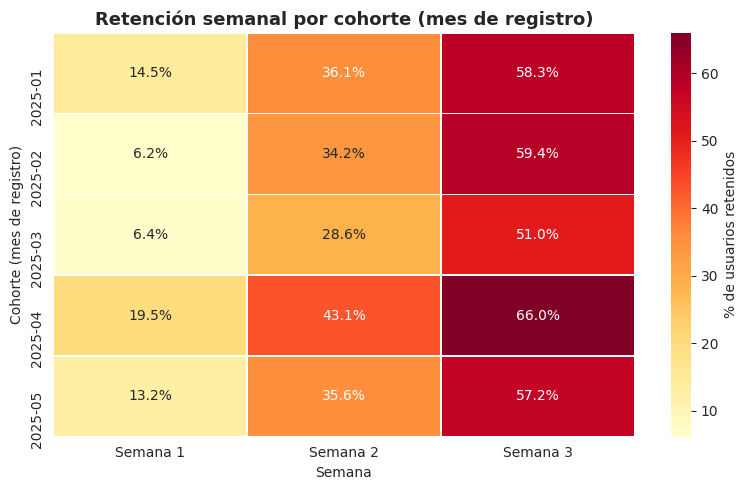

In [ ]:
retencion = cohorte_final.copy()
retencion['mes_cohorte'] = pd.to_datetime(retencion['mes_cohorte']).dt.strftime('%Y-%m')

for w in (1, 2, 3):
    retencion[f'semana_{w}'] = (retencion[f'retenido_w{w}'] / retencion['total_usuarios_cohorte'] * 100).round(2)

retencion[['mes_cohorte', 'total_usuarios_cohorte', 'semana_1', 'semana_2', 'semana_3']]

import matplotlib.pyplot as plt
import seaborn as sns

mapa = retencion.set_index('mes_cohorte')[['semana_1', 'semana_2', 'semana_3']]
mapa.columns = ['Semana 1', 'Semana 2', 'Semana 3']

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(mapa, annot=mapa.round(1).astype(str) + '%', fmt='', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': '% de usuarios retenidos'}, ax=ax)
ax.set_title('Retención semanal por cohorte (mes de registro)', fontsize=13, fontweight='bold')
ax.set_xlabel('Semana')
ax.set_ylabel('Cohorte (mes de registro)')
plt.tight_layout()
plt.show()

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado**
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** No existe diferencia significativa entre la tasa de conversión de los usuarios con el diseño actual (control) y el nuevo diseño de la interfaz
   - **H₁ (Hipótesis alternativa):** Sí existe una diferencia significativa en la tasa de conversión entre ambos grupos de la interfaz del checkout.
**Test estadístico:** Prueba Z de dos proporciones (proportions_ztest), ya que estamos comparando dos proporciones independientes (tasas de conversión binarias: 0 = no compró, 1 = compró).
**Nivel de significancia alpha:** 0.05 (5%).

In [ ]:
# tu código aquí
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

df_exp = pd.read_csv('/datasets/experiment_checkout_ui.csv')

print("Primeros registros del experimento:")
display(df_exp.head())

Primeros registros del experimento:


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [ ]:
conversion_summary = df_exp.groupby('variante')['convirtio'].agg(['count', 'sum', 'mean'])
conversion_summary.columns = ['total_usuarios', 'total_convertidos', 'tasa_conversion']
print("\nResumen de conversión por variante:")
display(conversion_summary)

control = df_exp[df_exp['variante'] == 'control']['convirtio']
treatment = df_exp[df_exp['variante'] == 'tratamiento']['convirtio']

successes = [treatment.sum(), control.sum()]
nobs = [len(treatment), len(control)]


Resumen de conversión por variante:


,total_usuarios,total_convertidos,tasa_conversion
variante,,,
control,4965,779,0.156898
tratamiento,5035,820,0.162860


In [ ]:
z_stat, p_value = proportions_ztest(successes, nobs)

print(f"\n--- Resultados del Test Estadístico ---")
print(f"Estadístico Z: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print("Resultado: Se rechaza la hipótesis nula (H₀). El cambio en la UI genera un impacto estadísticamente significativo.")
else:
    print("Resultado: No se rechaza la hipótesis nula (H₀). No hay evidencia estadística suficiente para afirmar que el cambio en la UI genera un impacto significativo.")


--- Resultados del Test Estadístico ---
Estadístico Z: 0.8133
P-value: 0.4161
Resultado: No se rechaza la hipótesis nula (H₀). No hay evidencia estadística suficiente para afirmar que el cambio en la UI genera un impacto significativo.


---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

https://public.tableau.com/views/Book1_17933107524180/OverviewEjecutivo?:language=es-ES&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

https://public.tableau.com/views/Book1_17933107524180/DetalleDrill-through?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link
